# Defining the Game: Tic-Tac-Toe

## Bài 1 – Định nghĩa trò chơi Tic-Tac-Toe

**Yêu cầu của bài:**
1. Xác định cách biểu diễn trạng thái, hành động hợp lệ, mô hình chuyển trạng thái, trạng thái kết thúc và hàm lợi ích.
2. Chạy các ví dụ, quan sát cách đánh số ô, thử các hàm `actions()`, `result()`, `terminal()`, `utility()`, `check_board()`, `show_board()`.
3. Thực nghiệm cơ sở: cho hai `random_player` chơi với nhau **1.000 ván**, ghi lại số ván X thắng, O thắng, hòa và nhận xét lợi thế của người đi trước.

Các ô có tiêu đề **Giải thích** và **Nhận xét** là phần bổ sung bằng tiếng Việt. File `tictactoe.py` được giữ nguyên, không sửa.

## The Search Problem

A general search problem is defined in the following way:

* **Initial State:** Empty $3 \times 3$ board. It is the move for $x$.
* **Actions:** Place your symbol on any empty square.
* **Transition function:** You symbol is placed on the board according to the action. The opponent
    places her symbol. From our viewpoint this makes the environment non-deterministic.
* **Goal state:** A win (three symbols in a row, column or diagonal). 
* **Path cost:** number of moves.
  
Since Tic-tac-toe is a game, we will use the more specializes components (see Chapter 5):
* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

**Notes:**

* To define the goal state we will use a test for a **terminal state** (game is over) and a **utility function** (win or loose). 
* We will use DFS which is not optimal. So will probably not find the solution with the lowest path cost, i.e., win with the smallest number of moves. Therefore, we drop the path cost all together.

**Giải thích: trò chơi cũng là một bài toán tìm kiếm**

Ở các bài tìm kiếm trước, chỉ có mình mình hành động. Trong trò chơi có thêm **đối thủ**, nên sau mỗi nước của mình, bàn cờ còn thay đổi theo cách mình không kiểm soát được. Vì vậy người ta mô tả trò chơi bằng 4 thành phần riêng:

| Thành phần | Câu hỏi nó trả lời |
| :-- | :-- |
| `Actions(s)` | Ở bàn cờ `s`, được phép đi những nước nào? |
| `Result(s, a)` | Đi nước `a` thì bàn cờ mới trông thế nào? |
| `Terminal(s)` | Ván đã kết thúc chưa (có người thắng hoặc hết ô)? |
| `Utility(s)` | Nếu đã kết thúc thì kết quả được mấy điểm: thắng +1, hòa 0, thua −1 |

Mọi thuật toán ở các bài sau (AND-OR, Minimax, Alpha-Beta, Monte Carlo) chỉ dùng đúng 4 hàm này. Vì thế hiểu kỹ 4 hàm này là hiểu được "luật chơi" mà thuật toán nhìn thấy.

## Problem Size

### State Space Estimates

Each state is a possible board. Each of the 9 squares can have 3 values (empty, x and o), but some boards are impossible (where a player has several sequences of 3).The number of states in the state space graph is less than $3^9$.

In [1]:
3**9

19683

A tighter bound for the search space size would be looking at all the ways we can choose $i = 1,2,3,...,9$ places from the board given by ${9 \choose i}$. Now we need to find all ways how we can choose half the symbols for player o which is given by ${i \choose \lfloor \frac{i}{2} \rfloor}$. 
Put together we get $\sum_{i=1}^9{{9 \choose i}{i \choose \lfloor \frac{i}{2} \rfloor}}$.

In [2]:
import math

print("level\tboards")
sum = 0

for i in range(1,9):
    sum += math.comb(9, i) * math.comb(i, math.floor(i/2))
    print(i, "\t", math.comb(9, i) , " x ", math.comb(i, math.floor(i/2)) , " = ",  math.comb(9, i) * math.comb(i, math.floor(i/2)))

sum

level	boards
1 	 9  x  1  =  9
2 	 36  x  2  =  72
3 	 84  x  3  =  252
4 	 126  x  6  =  756
5 	 126  x  10  =  1260
6 	 84  x  20  =  1680
7 	 36  x  35  =  1260
8 	 9  x  70  =  630


5919

This is an upper bound since it contains some infeasible boards where both players have 3 in a row.

**Giải thích:** $3^9 = 19683$ là đếm thô (mỗi ô có 3 khả năng). Công thức thứ hai chặt hơn vì X và O đi lần lượt, nên số quân O luôn bằng số quân X hoặc ít hơn đúng 1. Cả hai con số vẫn chỉ là **cận trên**, vì còn tính cả những bàn không thể xảy ra (ví dụ cả X và O cùng có 3 quân thẳng hàng). Ở phần thực nghiệm bên dưới mình đếm chính xác số trạng thái có thể xảy ra.

### Space and Time Complexity Using the Search Tree Estimates

For solving the problem, we use the search tree which can be significantly larger than the state space.
A search tree is a subgraph with all **cycles removed.** The standard implementation of DFS **cannot remove redundant paths** (i.e., getting to the same board by plcing symbols in a different order). Therefore, a state can be represented by several nodes in different branches! We observe the following:

* The complete search tree has a maximal depth $m=9$
* The max branching factor $b=9$ (for first move).

DFS has

* a space complexity of $O(bm)$ (current path plus frontier) and 
* a time complecity of $O(b^m)$ (number of expanded nodes).

In [3]:
# Space Complexity O(bm):
9*9

81

In [4]:
# Time Complexity O(b^m): 
9**9

387420489

The branching factor decreases after each move. The first level has a branching factor of 9, the second a branching factor of 8, etc. The total number of nodes is:

| <div style="width:100px">Level</div>      |  <div style="width:200px"># of nodes</div>   |
| :------------- | :---------------- |
| root       | $1$ |
| level 1    | $9 = 9!/8!$ |
| level 2    | $9 \times 8 = 9!/7!$ |
| level 2    | $9 \times 8 \times 7 = 9!/6!$ |
| ...        |  ... |
| level 9    | $9 \times 8 \times \dots \times 2 \times 1 = 9!$ |

The total number of game tree nodes is less (some games end early) than the sum of the nodes above. The upper bound for the number of nodes is

$\sum_{i = 0}^9 \frac{9!}{i!}$

In [5]:
sum = 1
partial_fac = 1
print("level\t# nodes")
print("root\t 1")

for i in range(9, 0, -1):
    partial_fac *= i
    sum += partial_fac 
    print(10-i, "\t", partial_fac)
    
sum

level	# nodes
root	 1
1 	 9
2 	 72
3 	 504
4 	 3024
5 	 15120
6 	 60480
7 	 181440
8 	 362880
9 	 362880


986410

Since some sequences are cut short because of a win, we expect fewer nodes in the game complete tree.

**Redundant paths:** The tree size estimation contains redundant paths.

**Cycles:** Tic-tac-toe does not have cycles (you cannot remove a played symbol).


**Giải thích: vì sao cây tìm kiếm lớn hơn nhiều so với số trạng thái?**

Cùng một bàn cờ có thể đến bằng nhiều thứ tự đi khác nhau. Ví dụ X đi ô 0 rồi ô 4, hay X đi ô 4 rồi ô 0 (O đi cùng các ô như nhau) đều ra cùng một bàn. Trong **không gian trạng thái**, bàn đó chỉ tính một lần. Trong **cây tìm kiếm**, mỗi thứ tự là một nút riêng. Vì vậy cây có tới khoảng 986 nghìn nút (cận trên), trong khi số bàn cờ khác nhau chỉ vài nghìn.

__Note:__ This size makes tic-tac-toe a very small problem that can be easily solved by tree search. Most games and real problems are too large and cannot be solved this way. For example, chess has an estimated state space size of $>10^{30}$. 
We will learn several methods that address this problem later.

## Implementation

We need to implement the following functions:

* `Actions(s)` Legal moves in state s.
* `Result(s, a)` Transition model.
* `Terminal(s)` Test for terminal states.
* `Utility(s)` Utility for player Max for terminal states.

The state (a board position) will be implemented as a vector (in Python this is a list) of length 9. The values are `' ', 'x', 'o'`. The actions are just the index in the list (0, 1, 2, ..., 8).


The implementation of these and some other helper functions can be found in [tictactoe.py](tictactoe.py)
and be imported from that file

**Giải thích: 5 thành phần của trò chơi trong `tictactoe.py`**

| Thành phần | Hàm trong `tictactoe.py` | Cách hoạt động |
| :-- | :-- | :-- |
| **Trạng thái** | danh sách 9 phần tử | Mỗi phần tử là `' '` (trống), `'x'` hoặc `'o'`. Ô được đánh số theo hàng: hàng trên 0 1 2, hàng giữa 3 4 5, hàng dưới 6 7 8 |
| **Hành động hợp lệ** `Actions(s)` | `actions(board)` | Trả về danh sách chỉ số các ô còn trống |
| **Chuyển trạng thái** `Result(s, a)` | `result(state, player, action)` | **Sao chép** bàn cờ rồi đặt quân của `player` vào ô `action`. Báo lỗi nếu ô đã có quân |
| **Kiểm tra kết thúc** `Terminal(s)` | `terminal(state)` | Đúng khi `check_board` trả về khác `'n'` |
| **Hàm lợi ích** `Utility(s)` | `utility(state, player='x')` | +1 nếu `player` thắng, 0 nếu hòa, −1 nếu thua, `None` nếu ván chưa xong |

Hàm phụ `check_board(state)` trả về `'x'` hoặc `'o'` (người thắng), `'d'` (hòa, hết ô) hoặc `'n'` (chưa xong, đi tiếp).

**Hai điểm cần để ý:**
- `result()` tạo bàn cờ **mới**, không sửa bàn cũ. Điều này quan trọng khi tìm kiếm: thuật toán thử nhiều nhánh từ cùng một bàn, nên không được làm hỏng bàn gốc.
- Trạng thái không ghi "đến lượt ai". Lượt đi được suy ra từ số quân: X luôn đi trước, nên nếu số quân X bằng số quân O thì đến lượt X, còn không thì đến lượt O.

In [6]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", "https://raw.githubusercontent.com/mhahsler/CS7320-AI/master/Games/")

**Lưu ý:** hàm `download` chỉ tải khi chưa có file. Vì `base_url` ở đây là `"."` chứ không phải đường link thật, bạn cần để `tictactoe.py` **cùng thư mục** với notebook thì mới chạy được. Theo quy định của nhóm, không sửa file này.

In [7]:
from tictactoe import empty_board, actions, result, terminal, utility
from tictactoe import show_board, show_board_text

## Examples

In [8]:
board = empty_board()
board[0] = 'x'; board[3] = 'x'; board[6] = 'x'; board[1] = 'o'; board[4] = 'o'  
display(board)

['x', 'o', ' ', 'x', 'o', ' ', 'x', ' ', ' ']

In [9]:
show_board_text(board)

[['x' 'o' ' ']
 ['x' 'o' ' ']
 ['x' ' ' ' ']]


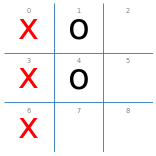

In [10]:
show_board(board)

In [11]:
actions(board)

[2, 5, 7, 8]

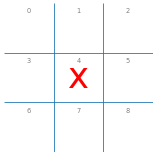

In [12]:
board2 = empty_board()
board2 = result(board2, 'x', 4)
show_board(board2)

In [13]:
print(terminal(board))
print(terminal(board2))

True
False


### Thử thêm các hàm còn lại

Đề yêu cầu thử cả `utility()`, `check_board()` và xem `result()` xử lý nước đi sai thế nào.

check_board(board) = x
utility theo góc nhìn x: 1
utility theo góc nhìn o: -1

check_board(board2) = n | utility = None



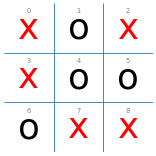

check_board(board_draw) = d | terminal = True | utility = 0

other('x') = o | other('o') = x


In [14]:
from tictactoe import check_board, other

# Bàn cờ ở ví dụ trên: x có 3 quân ở cột trái (ô 0, 3, 6)
print("check_board(board) =", check_board(board))
print("utility theo góc nhìn x:", utility(board, 'x'))
print("utility theo góc nhìn o:", utility(board, 'o'))
print()

# Bàn cờ chưa kết thúc: utility không xác định (None)
print("check_board(board2) =", check_board(board2), "| utility =", utility(board2))
print()

# Một ván hòa: hết ô mà không ai có 3 quân thẳng hàng
board_draw = ['x', 'o', 'x',
              'x', 'o', 'o',
              'o', 'x', 'x']
show_board(board_draw)
print("check_board(board_draw) =", check_board(board_draw),
      "| terminal =", terminal(board_draw),
      "| utility =", utility(board_draw))
print()
print("other('x') =", other('x'), "| other('o') =", other('o'))

In [15]:
# result() không sửa bàn cũ, và báo lỗi khi đi vào ô đã có quân
b = empty_board()
b_moi = result(b, 'x', 4)
print("Bàn cũ:", b)
print("Bàn mới:", b_moi)

try:
    result(b_moi, 'o', 4)   # ô 4 đã có x
except Exception as e:
    print("Báo lỗi đúng như mong đợi:", e)

Bàn cũ: [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']
Bàn mới: [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' ']
Báo lỗi đúng như mong đợi: Illegal action 4 by player o!


**Nhận xét:**
- Cùng một bàn cờ x thắng, `utility` cho +1 với góc nhìn của x và −1 với góc nhìn của o. Hàm lợi ích luôn tính **theo góc nhìn của người chơi được chỉ định**, mặc định là x (người chơi Max).
- Với bàn chưa kết thúc, `utility` trả về `None`. Các thuật toán tìm kiếm dựa vào đây để biết lúc nào phải dừng và lúc nào phải đi tiếp.
- `result()` trả về bàn mới, bàn cũ vẫn trống. Đi vào ô đã có quân thì bị báo lỗi, nên các tác tử chỉ được chọn trong `actions()`.

### Đếm chính xác số trạng thái có thể xảy ra

Đi từ bàn rỗng, X đi trước, thử mọi nước hợp lệ và dừng khi ván kết thúc. Mỗi bàn cờ chỉ đếm một lần.

In [16]:
def reachable_states():
    """Tập các bàn cờ có thể xuất hiện trong một ván thật."""
    seen = set()
    stack = [(tuple(empty_board()), 'x')]
    while stack:
        s, p = stack.pop()
        if s in seen:
            continue
        seen.add(s)
        if terminal(list(s)):
            continue          # ván đã xong thì không đi tiếp
        for a in actions(list(s)):
            stack.append((tuple(result(list(s), p, a)), other(p)))
    return seen

states = reachable_states()
print("Số bàn cờ có thể xảy ra:", len(states))
# (ở trên notebook đã dùng tên biến `sum`, nên ở đây không gọi hàm sum() được)
print("Trong đó số bàn đã kết thúc:", len([s for s in states if terminal(list(s))]))
print("So với đếm thô 3^9 =", 3**9)

Số bàn cờ có thể xảy ra: 5478


Trong đó số bàn đã kết thúc: 958
So với đếm thô 3^9 = 19683


**Nhận xét:** Chỉ có 5.478 bàn cờ thật sự có thể xảy ra, nhỏ hơn nhiều so với 19.683 bàn của cách đếm thô. Tic-Tac-Toe là trò chơi rất nhỏ, nên máy tính có thể duyệt hết toàn bộ. Đây là lý do các bài sau giải được nó một cách tối ưu.

## Experiments


### Baseline: Randomized Player

A completely randomized player agent can be used as a weak baseline. A simple random agent and a the game environment
are implemented in [tictactoe.py](tictactoe.py) as `random_player()` and `play()`, respectively.

In [17]:
from tictactoe import random_player, play 

### Random vs. Random

Let a random player play another random player for 100 games and look at the number of wins.

In [18]:
%time display(play(random_player, random_player, N = 100))

{'x': 66, 'o': 23, 'd': 11}

CPU times: total: 0 ns
Wall time: 23.5 ms


_Note:_ It looks like the first player (x) has an advantage!

### Thực nghiệm cơ sở: Random vs. Random 1.000 ván

Đề yêu cầu chạy 1.000 ván. Mình cố định `seed` để chạy lại vẫn ra đúng con số này.

In [19]:
import numpy as np

np.random.seed(2026)   # cố định để kết quả lặp lại được
N = 1000
%time res = play(random_player, random_player, N = N)

print(res)
for k, ten in [('x', 'X thắng'), ('o', 'O thắng'), ('d', 'Hòa')]:
    print(f"{ten}: {res[k]} ván ({res[k] / N:.1%})")

CPU times: total: 0 ns
Wall time: 172 ms
{'x': 596, 'o': 282, 'd': 122}
X thắng: 596 ván (59.6%)
O thắng: 282 ván (28.2%)
Hòa: 122 ván (12.2%)


### Kiểm chứng: xác suất chính xác khi hai bên đi ngẫu nhiên

1.000 ván vẫn có sai số do may rủi. Vì cây trò chơi nhỏ, mình tính được xác suất chính xác: ở mỗi bàn, mỗi nước hợp lệ có xác suất bằng nhau, rồi cộng dồn xác suất ra từng kết quả.

In [20]:
from functools import lru_cache

@lru_cache(maxsize=None)
def random_outcome_probs(state, player):
    """Xác suất (x thắng, o thắng, hòa) nếu từ 'state' cả hai bên đều đi ngẫu nhiên."""
    w = check_board(list(state))
    if w != 'n':
        return {'x': float(w == 'x'), 'o': float(w == 'o'), 'd': float(w == 'd')}
    acts = actions(list(state))
    p = {'x': 0.0, 'o': 0.0, 'd': 0.0}
    for a in acts:
        sub = random_outcome_probs(tuple(result(list(state), player, a)), other(player))
        for k in p:
            p[k] += sub[k] / len(acts)
    return p

exact = random_outcome_probs(tuple(empty_board()), 'x')
for k, ten in [('x', 'X thắng'), ('o', 'O thắng'), ('d', 'Hòa')]:
    print(f"{ten}: lý thuyết {exact[k]:.1%} | thực nghiệm {res[k] / N:.1%}")

X thắng: lý thuyết 58.5% | thực nghiệm 59.6%
O thắng: lý thuyết 28.8% | thực nghiệm 28.2%
Hòa: lý thuyết 12.7% | thực nghiệm 12.2%


**Nhận xét về lợi thế của người đi trước:**

- Trong 1.000 ván, **X thắng 596 ván, O thắng 282 ván, hòa 122 ván**. X thắng nhiều gấp khoảng 2 lần O.
- Con số này khớp với xác suất tính chính xác: X thắng khoảng 58,5%, O khoảng 28,8%, hòa khoảng 12,7%. Vậy lợi thế của X là thật, không phải do may rủi.
- **Vì sao X có lợi thế?**
  - X luôn có số quân bằng hoặc nhiều hơn O một quân. Khi bàn đầy, X có 5 quân còn O chỉ có 4.
  - X có thể thắng sớm nhất ở nước thứ 5 của ván (nước thứ 3 của X). O sớm nhất ở nước thứ 6. Khi đi ngẫu nhiên, ai có nhiều quân hơn trên bàn thì dễ vô tình xếp được 3 quân thẳng hàng trước.
- Đây là kết quả khi **cả hai chơi ngẫu nhiên**. Ở Bài 2 và Bài 3 sẽ thấy: nếu cả hai đều chơi tối ưu thì ván luôn hòa. Người đi trước có lợi, nhưng không đủ để chắc chắn thắng.
- Hai tác tử ngẫu nhiên này là **mốc so sánh** (baseline): các tác tử thông minh ở các bài sau phải thắng `random_player` nhiều hơn mức này mới được coi là tốt.

### Kết quả cho bảng tổng hợp (mục 4 của đề)

In [21]:
import time

def timed(agent):
    """Bọc một tác tử để đo tổng thời gian và số nước nó đã đi."""
    stats = {'moves': 0, 'time': 0.0}
    def wrapped(board, player = None):
        t0 = time.perf_counter()
        a = agent(board, player)
        stats['time'] += time.perf_counter() - t0
        stats['moves'] += 1
        return a
    return wrapped, stats

np.random.seed(7)
agent, stats = timed(random_player)
r = play(agent, random_player, N = 1000)
print("Tác tử: Random (đi X) | Đối thủ: Random | Số ván: 1000")
print(f"Thắng: {r['x']} | Hòa: {r['d']} | Thua: {r['o']}")
print(f"Thời gian TB/nước đi: {stats['time'] / stats['moves'] * 1000:.3f} ms")

Tác tử: Random (đi X) | Đối thủ: Random | Số ván: 1000
Thắng: 602 | Hòa: 135 | Thua: 263
Thời gian TB/nước đi: 0.007 ms
